In [1]:
import pandas as pd
from sklearn.svm import SVC
import numpy as np
from sklearn.metrics import r2_score
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('./dataset/nepal_trekking_cost.csv')

In [3]:
df.head()

,trek_duration_days,max_altitude_m,group_size,num_porters_guides,season,tourist_shoe_size,favorite_color,passport_last_digit,total_trip_cost_npr
0,18.0,4859.7,NaN,5.0,Peak,8,White,8,149000.0
1,13.0,2264.5,14.0,0.0,Off-season,8,Blue,4,89400.0
2,23.0,4828.2,7.0,4.0,Peak,5,Red,4,170000.0
3,24.0,2143.8,14.0,8.0,Peak,5,White,9,151500.0
4,14.0,1545.9,15.0,2.0,Off-season,7,White,8,81100.0


<Axes: ylabel='max_altitude_m'>

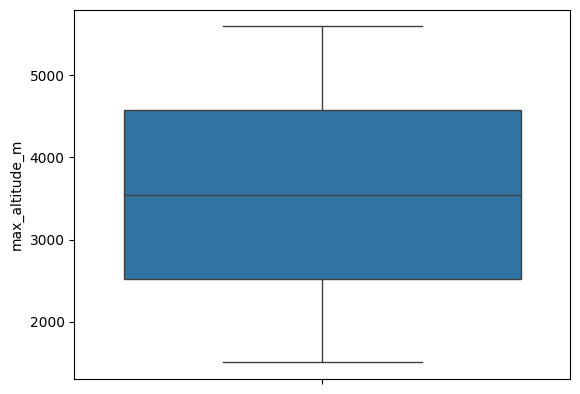

In [4]:
# plt.boxplot(df['max_altitude_m'])
# plt.show()
sns.boxplot(df['max_altitude_m'])

<Axes: ylabel='total_trip_cost_npr'>

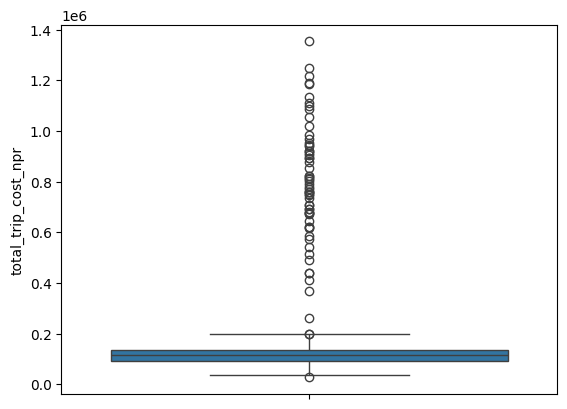

In [5]:
sns.boxplot(df['total_trip_cost_npr'])

In [6]:
Q1_num_porters_guides = df["num_porters_guides"].quantile(0.25)
Q3_num_porters_guides = df["num_porters_guides"].quantile(0.75)
IQR_num_porters_guides = Q3_num_porters_guides-Q1_num_porters_guides

In [7]:
lower_num_porters_guides=Q1_num_porters_guides-1.5*IQR_num_porters_guides
upper_num_porters_guides=Q3_num_porters_guides+1.5*IQR_num_porters_guides

In [8]:
df = df[df["num_porters_guides"] <= upper_num_porters_guides]
# df = df[df["num_porters_guides"] <= (upper_num_porters_guides and lower_num_porters_guides)]

In [9]:
Q1_trek_duration_days = df["trek_duration_days"].quantile(0.25)
Q3_trek_duration_days = df["trek_duration_days"].quantile(0.75)
IQR_trek_duration_days = Q3_trek_duration_days-Q1_trek_duration_days

In [10]:
lower_trek_duration_days=Q1_trek_duration_days-1.5*IQR_trek_duration_days
upper_trek_duration_days=Q3_trek_duration_days+1.5*IQR_trek_duration_days

In [11]:
df = df[df["trek_duration_days"] <= upper_trek_duration_days]

In [12]:
Q1_max_altitude_m = df["max_altitude_m"].quantile(0.25)
Q3_max_altitude_m = df["max_altitude_m"].quantile(0.75)
IQR_max_altitude_m = Q3_max_altitude_m-Q1_max_altitude_m

In [13]:
lower_max_altitude_m=Q1_max_altitude_m-1.5*IQR_max_altitude_m
upper_max_altitude_m=Q3_max_altitude_m+1.5*IQR_max_altitude_m


In [14]:
outliers = df[df["max_altitude_m"] > upper_max_altitude_m]

In [15]:
# len(outliers)

In [16]:
df = df[df["max_altitude_m"] <= upper_max_altitude_m]


In [17]:
Q1 = df["total_trip_cost_npr"].quantile(0.25)
Q3 = df["total_trip_cost_npr"].quantile(0.75)
IQR = Q3-Q1

In [18]:
lower=Q1-1.5*IQR
upper=Q3+1.5*IQR

In [19]:
print(lower)
print(upper)

29850.0
198850.0


In [20]:
outliers = df[df["total_trip_cost_npr"] > upper]

In [21]:
df = df[df["total_trip_cost_npr"] <= upper]

In [22]:
len(outliers)

50

In [23]:
df.describe()

,trek_duration_days,max_altitude_m,group_size,num_porters_guides,tourist_shoe_size,passport_last_digit,total_trip_cost_npr
count,2584.000000,2584.000000,2477.000000,2584.000000,2584.000000,2584.000000,2584.000000
mean,14.069659,3549.984791,8.020589,3.962848,9.050310,4.560759,113951.083591
std,6.696780,1192.278549,4.265424,2.558221,2.596899,2.912883,28349.458259
min,3.000000,1502.300000,1.000000,0.000000,5.000000,0.000000,27500.000000
25%,8.000000,2510.450000,4.000000,2.000000,7.000000,2.000000,93000.000000
50%,14.000000,3556.950000,8.000000,4.000000,9.000000,5.000000,114400.000000
75%,20.000000,4597.525000,12.000000,6.000000,11.000000,7.000000,134100.000000
max,25.000000,5599.000000,15.000000,8.000000,13.000000,9.000000,196800.000000


In [24]:
df.isnull().sum()

trek_duration_days       0
max_altitude_m           0
group_size             107
num_porters_guides       0
season                   0
tourist_shoe_size        0
favorite_color           0
passport_last_digit      0
total_trip_cost_npr      0
dtype: int64

In [25]:
# df = df.dropna()
# del df['season']

In [26]:
del df['tourist_shoe_size']
del df['passport_last_digit']
del df['favorite_color']


In [27]:
df["trek_duration_days"] = df["trek_duration_days"].fillna(df["trek_duration_days"].mean())
df["max_altitude_m"] = df["max_altitude_m"].fillna(df["max_altitude_m"].mean())
df["group_size"] = df["group_size"].fillna(df["group_size"].mean())
df["num_porters_guides"] = df["num_porters_guides"].fillna(df["num_porters_guides"].mean())

In [28]:
df["group_size"] = df["group_size"].fillna(df["group_size"].mean())

In [29]:
columns = pd.get_dummies(df['season']).astype(int)

In [30]:
del df['season']

In [31]:
df["group_size"] = df['group_size'].dropna()

In [32]:
df = pd.concat([df,columns],axis=1)

In [33]:
y = df['total_trip_cost_npr']
del df['total_trip_cost_npr']
X = df

In [34]:
y.shape

(2584,)

In [35]:
X.shape

(2584, 6)

In [36]:
# plt.scatter(df["trek_duration_days"], df["total_trip_cost_npr"],s=2)

# plt.xlabel("trek_duration_days Size")
# plt.ylabel("Total Trip Cost (NPR)")
# plt.title("trek_duration_days vs Total Trip Cost")
# plt.show()

In [37]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
import seaborn as sns
import matplotlib.pyplot as plt

In [38]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
)

In [39]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [40]:
model = LinearRegression()

In [41]:
model.fit(X_train_scaled,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](6,)","[21401.45,10742.12, 4773.68, 9140.74,-3744.13, 3744.13]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,1.137e+05
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,6
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(5)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](6,)","[64.33,46.75,45.68,45.05,44.3 , 0. ]"


In [42]:
y_pred = model.predict(X_test_scaled)

In [43]:
r2_score(y_test,y_pred)*100

92.61046474160894

In [151]:
df.info()

<class 'pandas.DataFrame'>
Index: 2603 entries, 1 to 2999
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   trek_duration_days  2603 non-null   float64
 1   max_altitude_m      2603 non-null   float64
 2   group_size          2603 non-null   float64
 3   num_porters_guides  2603 non-null   float64
 4   Off-season          2603 non-null   int64  
 5   Peak                2603 non-null   int64  
dtypes: float64(4), int64(2)
memory usage: 142.4 KB


In [41]:
df.shape

(2938, 6)

In [42]:
# df_sorted = df.sort_values(ascending=True)

# plt.figure(figsize=(10, 6))
# sns.scatterplot(
#     data=df_sorted,
#     x="trek_duration_days",
#     y="max_altitude_m",
#     hue="total_trip_cost_npr",
#     s=20,
#     palette={0: "dodgerblue", 1: "crimson"},
# )
# plt.show()

In [43]:
df.columns


Index(['trek_duration_days', 'max_altitude_m', 'group_size',
       'num_porters_guides', 'Off-season', 'Peak'],
      dtype='str')